# Will there be a bike? Progress report, model part

**Team 3, MIE1517.** For every Toronto Bike Share station we forecast the probability that at least one
classic bike, and at least one e-bike, will be docked there h = 2–15 minutes from now.

**Summary.**
<span style="color:#1f5fbf">[D1] Our best model so far is the MLP 2×256, dropout 0.3 network. On the validation days, on the station-times our table keeps (some count of classic bikes, e-bikes or free docks is 2 or less), it beats an honest 'what you see now' forecast (calibrated persistence) by a Brier skill score of 0.154 for classic bikes and 0.117 for e-bikes. Most of that is knowing the station and the hour: a look-up table that adds them (no learning) gets 0.115 / 0.085, and the network beats that table by 0.044 / 0.035.</span>
<span style="color:#1f5fbf">[D2] On the test days the skill against calibrated persistence is 0.125 / 0.092. For this model the test days were read once, for the chosen model only; the same days were scored once before (Nov 12) for our earlier count models, and nothing in this search was chosen on them.</span>
<span style="color:#1f5fbf">[D3] What is left: retrain on a larger dataset (data v2) whose test week nobody has read, longer history for the sequence models, and a rider-level evaluation; plan and dates in Section 8.</span>

All prose below is a draft: blue text marked [Dn] is draft text, red text marked [Cn] is a claim still to be
checked. Every number is printed from a table written by a script of the project.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
T, F = ROOT / "reports" / "tables", ROOT / "reports" / "figures"
pd.set_option("display.width", 100)
LABEL = {"persistence": "persistence", "calibrated persistence": "calibrated persistence",
         "station-hour persistence": "station-hour look-up", "climatology": "climatology",
         "logreg": "logistic regression", "lgbm": "LightGBM",
         "mlp_2x64_e8": "MLP 2x64 (base)", "mlp_2x256_do0.1": "MLP 2x256, dropout 0.1",
         "mlp_2x256_do0.3": "MLP 2x256, dropout 0.3",
         "gru64_3x256_do0.1": "GRU + 3x256, dropout 0.1"}

## 1. Data collected

<span style="color:#1f5fbf">[D4] We poll the public Toronto Bike Share feed (GBFS) every minute since Sep 29, with backup pollers, and add Environment Canada weather. The team table (data-v1) turns the polls into rows: for each station and anchor time t (every 10 min) it draws 3 random horizons h between 2 and 15 min. Each row holds the counts now and 10 and 30 min before, the station, the time of day and the weather, and the counts at t + h. Only anchors where some count (classic bikes, e-bikes or free docks) is 2 or less are kept, so every number below is on these station-times, where a rider may find no bike or no dock.</span>
<span style="color:#c00000">[C1] Pollers, weather source and the anchor rule as described in the team's data documentation; a coverage table (polls per day, gaps) from the data part of the team notebook should go here.</span>

The table gives the size of each split and how often the answer changes: the *flip rate* is the share of rows
whose 'at least one bike' status differs between t and t + h.
<span style="color:#1f5fbf">[D5] Status flips are rare: 2.6 % of val rows for classic bikes and 4.3 % for e-bikes, so 'what you see now' is already a strong forecast.</span>

In [2]:
data = pd.concat([pd.read_csv(T / "prob_data.csv"), pd.read_csv(T / "prob_test_data.csv")])
show = data[["split", "rows", "stations", "first_day", "last_day",
             "classic_base_rate", "ebike_base_rate",
             "classic_flip_rate", "ebike_flip_rate"]].round(3)
show.columns = ["split", "rows", "stations", "from", "to",
                "P(>=1 classic)", "P(>=1 e-bike)", "flip classic", "flip e-bike"]
show.set_index("split")

,rows,stations,from,to,P(>=1 classic),P(>=1 e-bike),flip classic,flip e-bike
split,,,,,,,,
train,7525845,1071,2026-09-29,2026-10-18,0.738,0.380,0.024,0.040
val,2083617,1071,2026-10-19,2026-10-23,0.717,0.363,0.026,0.043
test,1747660,1072,2026-10-24,2026-10-28,0.723,0.379,0.022,0.037


Five rows of one station on a validation morning (inputs, horizon h in minutes, and the two labels):

In [3]:
pd.read_csv(T / "prob_sample_rows.csv")

,t_local,h,classic_now,ebike_now,docks_now,classic_tm10,classic_tm30,capacity,temp_c,y_classic,y_ebike
0,2026-10-21T08:07:00-04:00,2.6,25,0,6,25,26,31,7.0,1,1
1,2026-10-21T08:07:00-04:00,3.6,25,0,6,25,26,31,7.0,1,1
2,2026-10-21T08:07:00-04:00,8.6,25,0,6,25,26,31,7.0,1,0
3,2026-10-21T08:17:00-04:00,3.7,26,0,5,25,24,31,7.0,1,0
4,2026-10-21T08:17:00-04:00,8.7,26,0,5,25,24,31,7.0,1,0


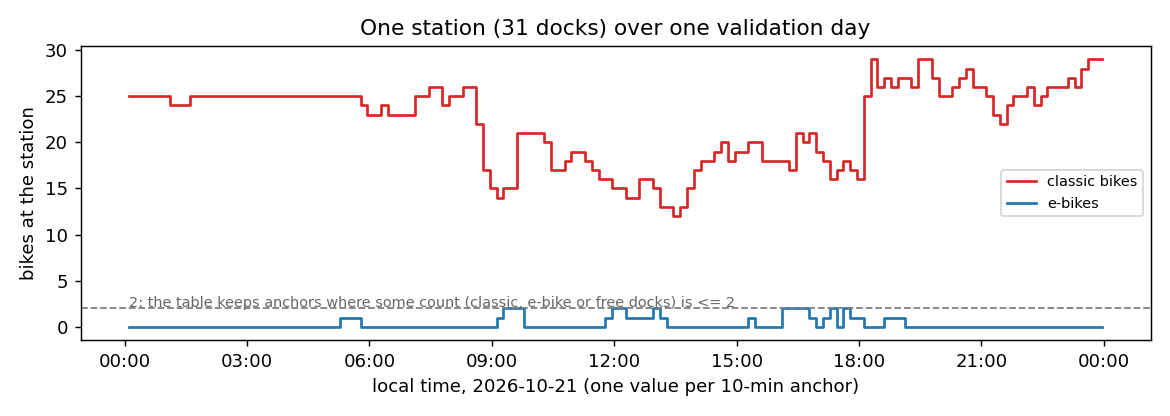

In [4]:
display(Image(filename=str(F / "prob_station_day.png"), width=850))

## 2. Task and score

**Output.** For each bike type, p = P(at least one bike at t + h), h = 2–15 min. One model covers all stations
and horizons (h is an input). Loss: binary cross-entropy.
<span style="color:#1f5fbf">[D6] We moved from forecasting the count (with MSE) to this probability because a rider's question is 'will there be a bike?', and a probability says how sure the answer is.</span>
<span style="color:#c00000">[C2] This replaces the team's count / MSE direction of Oct 28; the team has not confirmed it yet.</span>

**Score.** The Brier score, mean (p − y)², and the Brier skill score against a reference,
BSS = 1 − Brier_model / Brier_ref (0 = no better than the reference, 1 = perfect).
<span style="color:#1f5fbf">[D7] We do not use log loss against persistence: persistence says 0 or 1, so every miss costs log(0) = infinity. The Brier score is finite for 0/1 forecasts and is still a proper score.</span>

References, all fitted on the training days only:

| Reference | Forecast |
|---|---|
| Persistence | 1 if a bike is there now, else 0 |
| Calibrated persistence (headline) | P(bike at t + h given the count now and h) |
| Station-hour look-up (added after review; val only) | calibrated persistence corrected per station, hour of day and count now |
| Climatology | the station's rate at that hour of the week, ignoring the count now |

<span style="color:#1f5fbf">[D8] Calibrated persistence is our headline 'doing nothing': it uses only what the screen shows now, and it already knows that '1 bike now' is not a sure bike later; it beats raw persistence by 0.061 / 0.065 (classic / e-bike, val). The station-hour look-up is a stronger bar that needs a table per station and hour: it scores 0.115 / 0.085 against calibrated persistence. It was added after the test read, so it has no test score. Climatology ignores the count now and is far weaker (BSS against persistence -4.51 / -3.93).</span>

**Method: the score** (`score_prob.py`)

```python
def brier(p, y):
    """Mean squared error of the probability, per target column."""
    return ((np.asarray(p, np.float64) - y) ** 2).mean(axis=0)
```

```python
def bss(p, p_ref, y):
    """Brier skill score of p against the reference p_ref, per target column."""
    return 1 - brier(p, y) / brier(p_ref, y)
```

**Method: the headline reference**, fitted on the training rows only

```python
class CalibratedPersistence:
    """p = P(y = 1 | min(count now, CAP), h_target) from the train rows, per target, shrunk toward the count's rate.
    A (count, h) cell missing from train falls back to the count's rate over all h."""

    def fit(self, df):
        y = labels(df)
        self.table = {}
        for i, x in enumerate(TARGETS):
            c = np.minimum(df[f"{x}_now"].to_numpy(), CAP).astype(int)
            g = pd.DataFrame({"c": c, "h": df.h_target.to_numpy().astype(int), "y": y[:, i]})
            by_c = g.groupby("c").y.mean()
            cell = g.groupby(["c", "h"]).y.agg(["sum", "size"])
            prior = by_c.reindex(cell.index.get_level_values("c")).to_numpy()
            self.table[x] = ((cell["sum"] + K * prior) / (cell["size"] + K)).rename("p")
            self.table[x + "_by_c"] = by_c
            self.table[x + "_cmax"] = int(c.max())
        return self

    def predict(self, df):
        out = np.empty((len(df), len(TARGETS)))
        h = df.h_target.to_numpy().astype(int)
        for i, x in enumerate(TARGETS):  # a count above any count seen in train takes the top cell
            c = np.minimum(df[f"{x}_now"].to_numpy(), self.table[x + "_cmax"]).astype(int)
            idx = pd.MultiIndex.from_arrays([c, h], names=["c", "h"])
            p = self.table[x].reindex(idx).to_numpy().copy()
            miss = np.isnan(p)  # a (count, h) cell not in train: the count's rate over all h
            p[miss] = self.table[x + "_by_c"].reindex(c[miss]).to_numpy()
            out[:, i] = p
        assert not np.isnan(out).any(), "calibrated persistence: a count now never seen in train"
        return out
```

## 3. Model

**Label and inputs.** The label of bike type x is y = 1 if the count of x at t + h is at least 1.
<span style="color:#1f5fbf">[D9] The network takes the table's 20 numeric inputs: horizon h; classic, e-bike and free-dock counts now, 10 and 30 min ago; capacity; latitude and longitude; hour of day (sine and cosine); weekend; temperature; humidity; and two of them, `renting_now` and `returning_now`, are station-status flags ('accepts rentals / returns'), equal to 1 on every training and validation row, so they are constant and carry no information (18 inputs vary). They are standardised with the training mean and standard deviation. An 8-number embedding of the station is learned with the model. Two outputs give one logit per bike type.</span>

**Method: the label**

```python
def labels(df):
    """1 if at least one bike of the type is at the station at t + h. [n, len(TARGETS)] float64"""
    return df[[f"y_{x}" for x in TARGETS]].to_numpy(np.float64)
```

**Method: the network** (`37_model_search.py`; config of the chosen model: `Config(arch='mlp', depth=2, width=256, emb=8, gru=0, lr=0.001, batch=4096, dropout=0.3, wd=0.0)`)

```python
class Net(nn.Module):
    def __init__(self, cfg, n_inputs, n_stations):
        super().__init__()
        self.cfg = cfg
        self.station = nn.Embedding(n_stations + 1, cfg.emb)
        if cfg.arch == "gru":
            self.rnn = nn.GRU(len(SEQ[0]) + len(SEQ), cfg.gru, batch_first=True)
            self.register_buffer("seq_idx", torch.tensor(SEQ_IDX))
            self.register_buffer("ctx_idx", torch.tensor(CTX_IDX))
            self.register_buffer("step_onehot", torch.eye(len(SEQ)))
            n_in = len(CTX_IDX) + cfg.gru + cfg.emb
        else:
            n_in = n_inputs + cfg.emb
        layers = []
        for _ in range(cfg.depth):
            layers += [nn.Linear(n_in, cfg.width), nn.ReLU()]
            if cfg.dropout > 0:
                layers.append(nn.Dropout(cfg.dropout))
            n_in = cfg.width
        layers.append(nn.Linear(n_in, len(TARGETS)))
        self.net = nn.Sequential(*layers)

    def forward(self, x, station):
        e = self.station(station)
        if self.cfg.arch == "gru":
            seq = x[:, self.seq_idx]  # [n, 3 steps, 3 counts]
            seq = torch.cat([seq, self.step_onehot.expand(len(x), -1, -1)], dim=2)
            _, hT = self.rnn(seq)
            return self.net(torch.cat([x[:, self.ctx_idx], hT[0], e], dim=1))
        return self.net(torch.cat([x, e], dim=1))
```

**Method: training** (condensed from `train()` in `46_prob_search.py`). Adam, learning rate 10⁻³, batch 4,096,
one pass over the 7,525,845 training rows per epoch, up to 30 epochs; keep the epoch with the lowest
validation cross-entropy; stop after 3 epochs without improvement.

```python
model = Net(cfg, n_inputs=20, n_stations=1071)          # one extra embedding row for unseen stations
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()                         # binary cross-entropy on the 2 logits
best, best_epoch = inf, 0
for epoch in range(1, 31):
    model.train()
    for idx in torch.randperm(len(x_train)).split(4096):
        loss = loss_fn(model(x_train[idx], station_train[idx]), y_train[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    val = cross_entropy(sigmoid(model(x_val, station_val)), y_val)
    if val < best:
        best, best_epoch, best_state = val, epoch, copy(model.state_dict())
    elif epoch - best_epoch >= 3:                        # patience 3
        break
model.load_state_dict(best_state)
```

## 4. Step by step: from references to the chosen model (validation days)

We trained four networks with three seeds each (0, 1, 2), so a gap between models can be judged against
the spread over seeds, plus LightGBM (gradient-boosted trees, three seeds) and logistic regression.
Validation: Oct 19–23. The rule to pick the model was fixed before any run: the lowest validation Brier
(mean of the two bike types), preferring a network with fewer parameters if it is within noise.

In [5]:
s = pd.read_csv(T / "prob_summary.csv")
runs = pd.read_csv(T / "prob_runs.csv")
order = ["persistence", "climatology", "calibrated persistence", "station-hour persistence",
         "logreg", "lgbm", "mlp_2x64_e8", "mlp_2x256_do0.1", "mlp_2x256_do0.3",
         "gru64_3x256_do0.1"]
a = s[s.subset == "all"].set_index(["model", "target"])
def cell(m, x, k="bss_calpers"):
    r = a.loc[(m, x)]
    sd = r[f"{k}_sd"]
    return f"{r[f'{k}_mean']:.3f}" + ("" if np.isnan(sd) else f" ± {sd:.4f}")
params = runs.groupby("name").n_params.first()
tab = pd.DataFrame({
    "classic": [cell(m, "classic") for m in order],
    "e-bike": [cell(m, "ebike") for m in order],
    "vs look-up": [f"{a.loc[(m, 'classic')].bss_sthour_mean:.3f} / "
                   f"{a.loc[(m, 'ebike')].bss_sthour_mean:.3f}" for m in order],
    "params": ["" if pd.isna(params.get(m)) else f"{int(params[m]):,}" for m in order]},
    index=[LABEL[m] for m in order])
print("Validation BSS against calibrated persistence (mean ± sd over 3 seeds),")
print("and against the station-hour look-up (classic / e-bike)")
tab

Validation BSS against calibrated persistence (mean ± sd over 3 seeds),
and against the station-hour look-up (classic / e-bike)


,classic,e-bike,vs look-up,params
persistence,-0.065,-0.070,-0.203 / -0.169,
climatology,-4.869,-4.275,-5.634 / -4.765,
calibrated persistence,0.000,0.000,-0.130 / -0.093,
station-hour look-up,0.115,0.085,0.000 / 0.000,
logistic regression,-0.000,0.002,-0.131 / -0.091,42
LightGBM,0.151 ± 0.0004,0.114 ± 0.0005,0.040 / 0.031,
MLP 2x64 (base),0.145 ± 0.0063,0.114 ± 0.0028,0.034 / 0.031,"14,722"
"MLP 2x256, dropout 0.1",0.153 ± 0.0006,0.116 ± 0.0007,0.043 / 0.034,"82,306"
"MLP 2x256, dropout 0.3",0.154 ± 0.0002,0.117 ± 0.0006,0.044 / 0.035,"82,306"
"GRU + 3x256, dropout 0.1",0.152 ± 0.0014,0.115 ± 0.0006,0.042 / 0.033,"176,002"


In [6]:
ch = json.loads((T / "prob_choice.json").read_text())
for n, r in ch["nets"].items():
    print(f"{LABEL[n]:26s} mean Brier {r['mean_brier']:.5f} ± {r['sd_brier']:.5f}"
          f"  ({r['n_params']:,} params)")
print("chosen by the rule:", LABEL[ch["chosen"]])

MLP 2x64 (base)            mean Brier 0.02826 ± 0.00013  (14,722 params)
MLP 2x256, dropout 0.1     mean Brier 0.02813 ± 0.00001  (82,306 params)
MLP 2x256, dropout 0.3     mean Brier 0.02809 ± 0.00001  (82,306 params)
GRU + 3x256, dropout 0.1   mean Brier 0.02815 ± 0.00001  (176,002 params)
chosen by the rule: MLP 2x256, dropout 0.3


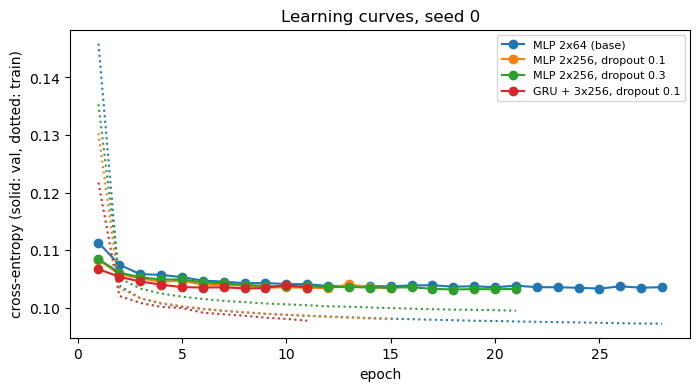

In [7]:
cur = pd.read_csv(T / "prob_curves.csv")
fig, ax = plt.subplots(figsize=(8, 4))
for n, c in zip(["mlp_2x64_e8", "mlp_2x256_do0.1", "mlp_2x256_do0.3",
                 "gru64_3x256_do0.1"], ["C0", "C1", "C2", "C3"]):
    g = cur[cur.run_id == f"p_{n}_seed0"]
    ax.plot(g.epoch, g.val_bce, "o-", color=c, label=LABEL[n])
    ax.plot(g.epoch, g.train_bce, ":", color=c)
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy (solid: val, dotted: train)")
ax.set_title("Learning curves, seed 0")
ax.legend(fontsize=8)
plt.show()

**Result.** <span style="color:#1f5fbf">[D10] The models that know the station all clear the bar by about the same amount. The chosen MLP 2×256, dropout 0.3 scores 0.154 ± 0.0002 (classic) and 0.117 ± 0.0006 (e-bike; ± = sd over seeds); the other networks and LightGBM are within 0.0085 of it. The day-to-day spread is larger than the seed spread: over the five validation days the chosen model ranges 0.146–0.163 (classic) and 0.112–0.121 (e-bike).</span>

<span style="color:#1f5fbf">[D11] What the gain needs (LightGBM, seed 0, one input set at a time; table below): the counts now and h alone give 0.011 / 0.006; adding the lag counts gives 0.080 / 0.061; all inputs without any station information (no station index, location or capacity) give 0.090 / 0.071; with the location and capacity but no station index 0.148 / 0.112; with the station but without the lag counts 0.150 / 0.113. So the station (its location is enough) is the largest part of the gain, and once the station is known the lag counts add little. Logistic regression, which has neither the station nor a non-linear use of the inputs, only matches calibrated persistence (-0.000 / 0.002).</span>

In [8]:
ab = pd.read_csv(T / "prob_ablation.csv").set_index("name")
names = {"lgbm_all": "all inputs + station index",
         "lgbm_no_station_idx": "no station index (location kept)",
         "lgbm_no_station_info": "no station index, location, capacity",
         "lgbm_no_lags": "no lag counts (station kept)",
         "lgbm_counts_lags_h": "counts now + lags + h only",
         "lgbm_counts_now_h": "counts now + h only"}
print("LightGBM (seed 0) on input subsets: val BSS against calibrated persistence")
pd.DataFrame({"classic": ab.bss_calpers_classic_all, "e-bike": ab.bss_calpers_ebike_all}
             ).rename(index=names).round(3)

LightGBM (seed 0) on input subsets: val BSS against calibrated persistence


,classic,e-bike
name,,
all inputs + station index,0.151,0.114
no station index (location kept),0.148,0.112
"no station index, location, capacity",0.090,0.071
no lag counts (station kept),0.150,0.113
counts now + h only,0.011,0.006
counts now + lags + h only,0.080,0.061


<span style="color:#1f5fbf">[D12] The rule picked MLP 2×256, dropout 0.3. Its lead is small. Gaps against calibrated persistence, classic / e-bike, with z = gap / √(seed variance + station-sampling variance): over dropout 0.1 +0.0010 / +0.0012 (z 1.6 / 2.1, a tie: same size, and the rule cannot separate them); over the GRU +0.0014 / +0.0019 (z 1.4 / 3.1); over LightGBM +0.0031 / +0.0034 (z 2.6 / 4.6); over the base 2×64 +0.0085 / +0.0034 (z 2.1 / 2.0). With 3 seeds per model these z values are rough. The candidates were picked from the count search on the same validation days.</span>
<span style="color:#1f5fbf">[D13] Part of the base's gap was early stopping: rerun with patience 6 (after the reviews), its seeds stop at epochs 25/19/24 and reach 0.150 / 0.115, against 0.145 / 0.114 with patience 3. The rule would still keep MLP 2×256, dropout 0.3 (gap 0.000084 in mean Brier against a threshold of 0.000063); the choice is not changed, since the test days were already read.</span>

## 5. Where the model helps, and is it calibrated? (validation days)

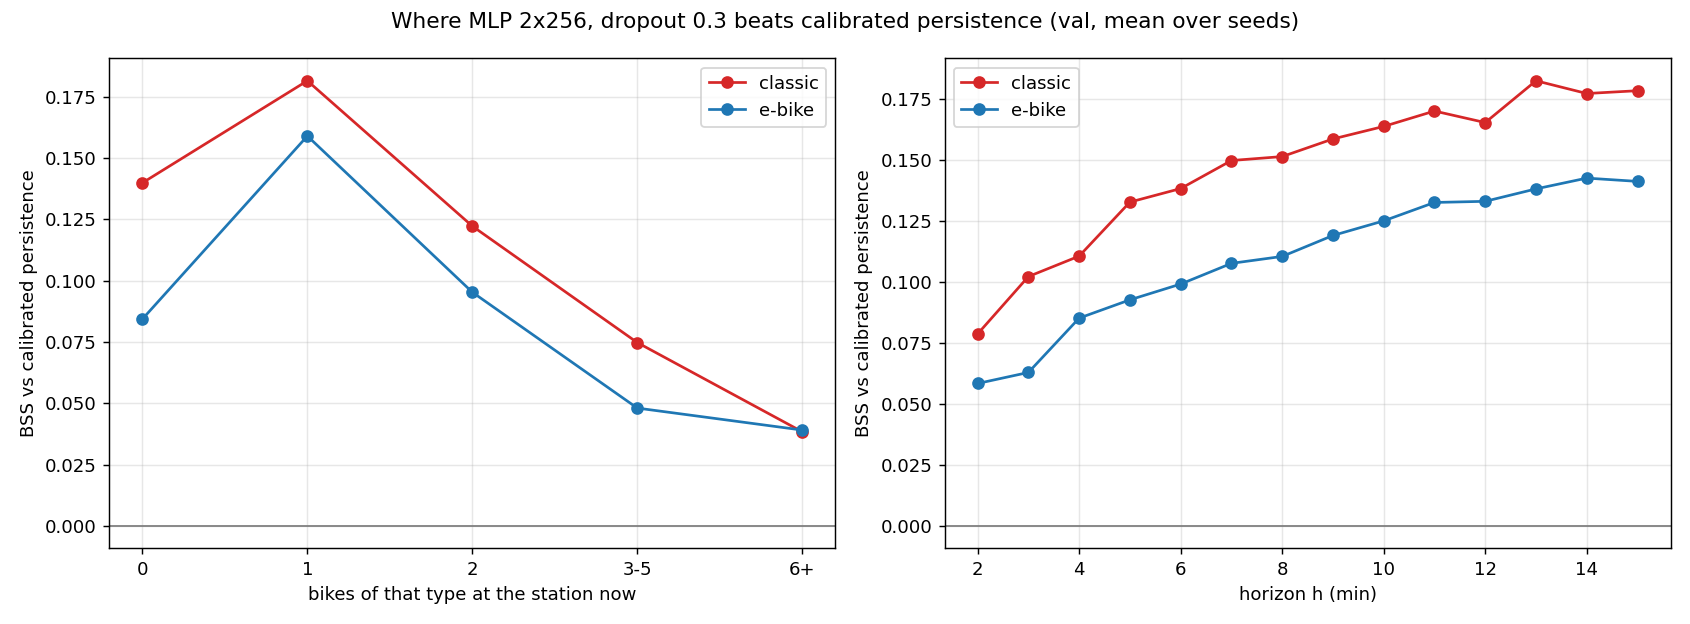

In [9]:
display(Image(filename=str(F / "prob_where.png"), width=900))

<span style="color:#1f5fbf">[D14] Measured as skill, the model helps most when one bike is left: BSS 0.182 (classic) and 0.159 (e-bike) against calibrated persistence, against 0.038 / 0.039 with 6 or more bikes (on test: 0.145 / 0.123 at one bike). Stations with no bike now matter as much for classic bikes: there the question is whether a bike will arrive. The gain also grows with the horizon, from 0.079 / 0.058 at h = 2 min to 0.177 / 0.143 at h = 14 min (hypothesis: the further ahead, the more the count now leaves open).</span>
<span style="color:#1f5fbf">[D15] Share of the total Brier reduction against calibrated persistence: rows with 0 bikes now give 46 % (classic) / 37 % (e-bike), rows with 1 bike 47 % / 59 %.</span>

<span style="color:#1f5fbf">[D16] In rider terms (validation only): when one bike is there now, it is gone by t + h in 7.6 % of cases (classic; 9.2 % for e-bikes). A warning on the 10 % of these cases with the lowest forecast would catch 48 % of the times the bike is gone (41 % for e-bikes), and be right 36 % / 37 % of the time, so about 2 in 3 warnings would be false alarms. Ranking within each horizon gives nearly the same catch (46 % / 38 %). The same warning from calibrated persistence catches 13 % / 14 %, and from the station-hour look-up 43 % / 36 %. The base MLP and LightGBM catch about as much as the chosen model, so this is a property of the models that know the station, not of this one.</span>

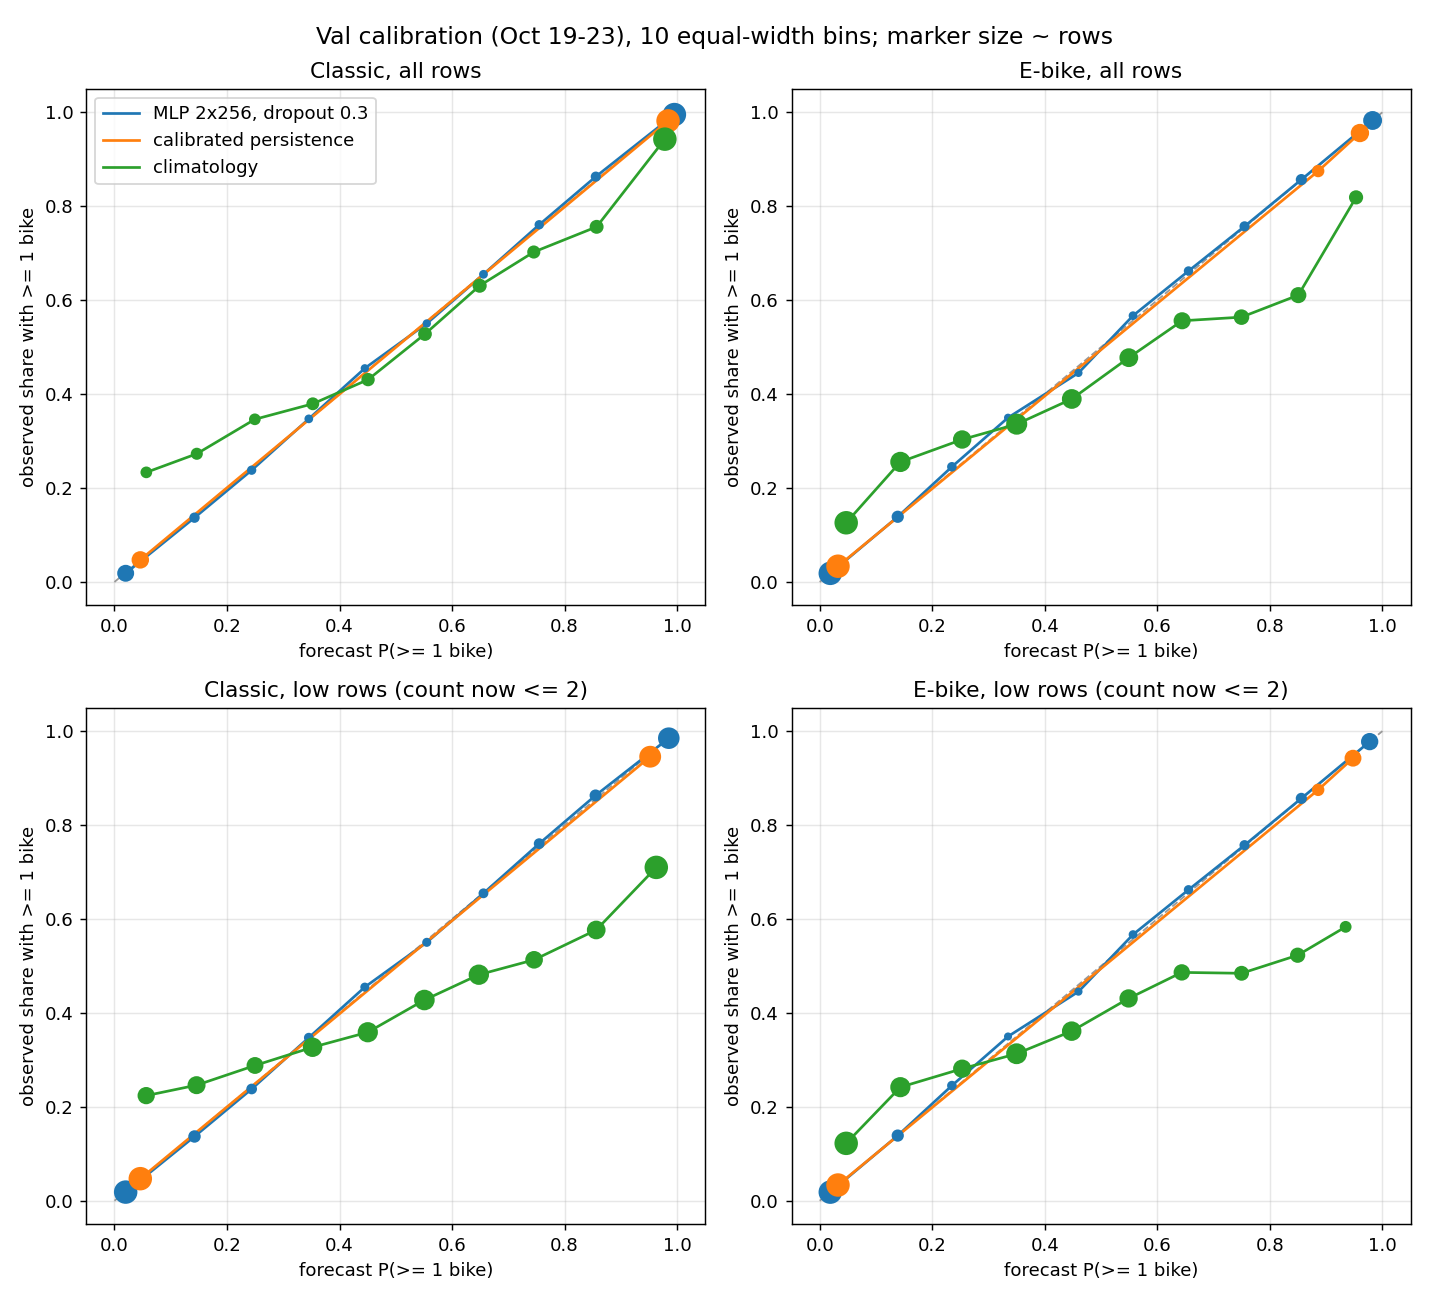

In [10]:
display(Image(filename=str(F / "prob_reliability.png"), width=760))

<span style="color:#1f5fbf">[D17] On the validation days the forecasts are well calibrated: in every bin with at least 1,000 rows the observed share is within 0.010 (classic) and 0.015 (e-bike) of the forecast (seed 0; the epoch was picked on these days, so this is a best case). Climatology is not calibrated (off by up to 0.24 for e-bikes, all rows): each of its station × hour-of-week cells holds only 2.7 training days on average, and with 10 times more shrinkage its e-bike gap falls to 0.08. Its high Brier score comes from ignoring the count now: more shrinkage lowers it only from 0.210 to 0.198 (e-bike).</span>

## 6. Test result

<span style="color:#1f5fbf">[D18] The test days (Oct 24–28) were read once for this model, for the chosen model only, after the choice; the protocol was committed before the read. The same days had been scored once before (Nov 12, early morning) for our earlier count models; nothing in this search was chosen on them. Nothing was tuned after the read.</span>

In [11]:
t = pd.read_csv(T / "prob_test_summary.csv")
t = t[t.subset == "all"]
t = t[t.model != "climatology"].copy()
t["model"] = t.model.map(lambda m: LABEL.get(m, m))
t = t.rename(columns={"brier_mean": "Brier", "bss_pers_mean": "BSS vs persistence",
                      "bss_calpers_mean": "BSS vs cal. pers.", "bss_calpers_sd": "sd (seeds)"})
print("Test, Oct 24-28, all table rows")
print(t[["model", "target", "Brier", "BSS vs persistence", "BSS vs cal. pers.",
         "sd (seeds)"]].to_string(index=False, float_format=lambda x: f"{x:.4f}",
                                  na_rep=""))

Test, Oct 24-28, all table rows
                 model  target  Brier  BSS vs persistence  BSS vs cal. pers.  sd (seeds)
MLP 2x256, dropout 0.3 classic 0.0186              0.1721             0.1254      0.0006
MLP 2x256, dropout 0.3   ebike 0.0320              0.1443             0.0924      0.0005
           persistence classic 0.0225              0.0000            -0.0564            
calibrated persistence classic 0.0213              0.0534             0.0000            
           persistence   ebike 0.0374              0.0000            -0.0607            
calibrated persistence   ebike 0.0352              0.0572             0.0000            


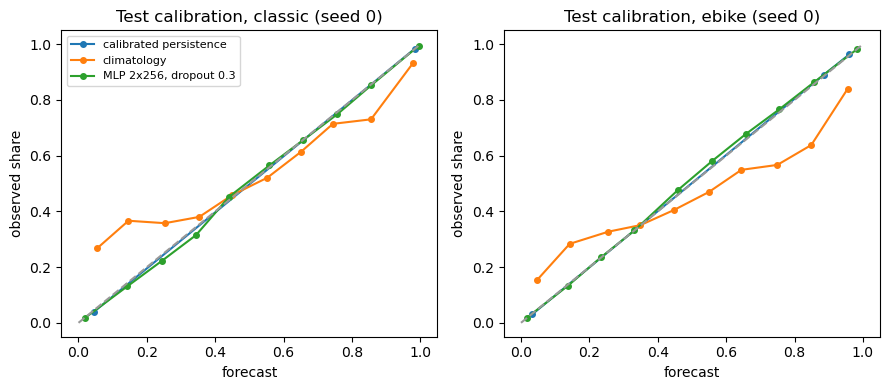

In [12]:
tr = pd.read_csv(T / "prob_test_reliability.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, x in zip(axes, ["classic", "ebike"]):
    for m, g in tr[(tr.target == x) & (tr.rows >= 1000)].groupby("model"):
        ax.plot(g.p_mean, g.y_rate, "o-", ms=4, label=LABEL.get(m, m))
    ax.plot([0, 1], [0, 1], "--", color="0.6")
    ax.set_title(f"Test calibration, {x} (seed 0)")
    ax.set_xlabel("forecast")
    ax.set_ylabel("observed share")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
rows = []
for split, f in [("val", "prob_by_day.csv"), ("test", "prob_test_by_day.csv")]:
    t = pd.read_csv(T / f)
    m = t[t.model == "mlp_2x256_do0.3"].set_index(["group", "target"])
    p = t[t.model == "persistence"].set_index(["group", "target"])
    for day in sorted(m.index.get_level_values(0).unique()):
        rows.append({"split": split, "day": day,
                     "weekday": pd.Timestamp(day).day_name()[:3],
                     "rows": int(m.loc[(day, "classic"), "rows"]),
                     "flip classic": p.loc[(day, "classic"), "brier"],
                     "BSS classic": m.loc[(day, "classic"), "bss_calpers"],
                     "flip e-bike": p.loc[(day, "ebike"), "brier"],
                     "BSS e-bike": m.loc[(day, "ebike"), "bss_calpers"]})
print("Per day: flip rate (= persistence Brier) and BSS against calibrated persistence")
pd.DataFrame(rows).round(4).set_index(["split", "day"])

Per day: flip rate (= persistence Brier) and BSS against calibrated persistence


weekday    rows  flip classic  BSS classic  flip e-bike  BSS e-bike
split day                                                                           
val   2026-10-19     Mon  419193        0.0251       0.1488       0.0411      0.1117
      2026-10-20     Tue  415263        0.0272       0.1569       0.0414      0.1205
      2026-10-21     Wed  416506        0.0265       0.1632       0.0430      0.1195
      2026-10-22     Thu  417434        0.0273       0.1539       0.0440      0.1209
      2026-10-23     Fri  415221        0.0259       0.1461       0.0437      0.1122
test  2026-10-24     Sat  416958        0.0232       0.1169       0.0405      0.0847
      2026-10-25     Sun  411343        0.0218       0.1106       0.0390      0.0779
      2026-10-26     Mon  421252        0.0251       0.1405       0.0385      0.1022
      2026-10-27     Tue  421548        0.0234       0.1266       0.0367      0.1017
      2026-10-28     Wed   76559        0.0024       0.2964       0.0087      0.1657

<span style="color:#1f5fbf">[D19] The gain holds on test but is smaller: 0.125 / 0.092 against calibrated persistence (validation 0.154 / 0.117) and 0.172 / 0.144 against persistence. Calibration is looser than on validation, in a systematic way: classic forecasts of 0.1–0.4 are 0.012–0.029 too high, e-bike forecasts of 0.4–0.7 0.018–0.022 too low. Calibrated persistence stays within 0.006 / 0.005.</span>
<span style="color:#c00000">[C3] About a third of the drop is the weekend: the test week starts on a Saturday and the validation days have no weekend. Weekends are harder even on the training days (in sample: weekdays 0.166, Saturdays 0.134, Sundays 0.128, classic). On test, Sat–Sun pooled give 0.114 / 0.081 and Mon–Tue 0.134 / 0.102; leaving the weekend out closes 29 % (classic) and 39 % (e-bike) of the gap to validation. The test weekdays are still below every validation day. The test week also has fewer flips (2.2 % against 2.6 %, classic), and the model's Brier score itself is lower on test (0.0186 against 0.0210): the reference improved more than the model. Calmer days tend to score lower (table above), but that is not all of it: the test Monday, with the same classic flip rate as the validation Monday (2.51 % against 2.51 %), still scores 0.140 against 0.149. Untested: how much is the calmer week and how much the distance from training (test days are 6–10 days after it, validation days 1–5).</span>
<span style="color:#1f5fbf">[D20] Oct 28 holds only the early-morning hours (76,559 rows). Dropping the 2,324 test rows at stations never seen in training changes the skill by at most 0.0002. The station-hour look-up was added after the test read and has no test score.</span>

## 7. Preliminary: data v2

<span style="color:#1f5fbf">[D21] A second, larger table (data v2) adds the days to Nov 10: 11,198,091 training rows (to 2026-10-27), and a validation week (2026-10-28 to 2026-11-03) and test week (2026-11-04 to 2026-11-10) of 5 weekdays and 2 weekend days each. Its validation week overlaps the data-v1 test days, so its numbers are not a second data-v1 test; its own test week has not been read. So far only a 1-epoch smoke test has run, with the earlier count target (MSE): its skill is 1 − MSE_model / MSE_persistence, not the Brier skill above, and only shows that the pipeline runs end to end.</span>

In [14]:
v2 = pd.read_csv(T / "data_v2_smoke_fwd.csv")
v2 = v2[(v2.subset == "all") & (v2.day_type == "all")]
print("PRELIMINARY: count target (MSE), 1 epoch, data-v2 validation week")
print(v2.pivot(index="model", columns="target", values="skill").round(3))

PRELIMINARY: count target (MSE), 1 epoch, data-v2 validation week
target  classic  ebike
model                 
lstm      0.061  0.064
mlp       0.070  0.077


## 8. What is left, and is it feasible?

<span style="color:#1f5fbf">[D22] Done: data collection (running since Sep 29), the dataset, the score and its references, a small model search, and a test score. Left, in order:</span>

1. <span style="color:#1f5fbf">[D23] Data v2 (Nov 16–19): retrain the chosen model and the station-hour look-up on the larger table and check the weekend days on its validation week.</span>
2. <span style="color:#1f5fbf">[D24] Longer history (Nov 19–22): give the GRU 60 min of past counts, which data v2 provides; freeze the final model on Nov 22 and score it once on the unread data-v2 test week (Nov 4–10).</span>
3. <span style="color:#1f5fbf">[D25] Rider-level evaluation (Nov 23–29): turn the probabilities into advice (e.g. 'go elsewhere' below a threshold) and count strandings avoided and false alarms per 100 trips.</span>
4. <span style="color:#1f5fbf">[D26] Video (Dec 6) and final report (Dec 11).</span>

<span style="color:#1f5fbf">[D27] Compute is not the limit: the 16 runs of this search took 3.8 h of run time, 0.9 h of wall time with several runs in parallel on one laptop; data v2 has 1.5 times the rows, so the same search should take about 1.3 h. The person time is the limit:</span>
<span style="color:#c00000">[C4] about 5 h per person per week (the team's budget from the proposal) leaves room for steps 1–3 if each person takes one.</span>

**Reproduce** (from `src/` of the project repository; this notebook only reads the tables these write):

```bash
python test_score_prob.py                       # checks of the score on toy cases
python 46_prob_search.py --logreg --lgbm --seed 0 1 2
python 46_prob_search.py --run mlp_2x64_e8 mlp_2x256_do0.1 mlp_2x256_do0.3 gru64_3x256_do0.1 --seed 0 1 2
python 47_prob_report.py                        # validation tables, the choice, figures
python 48_prob_test.py --dry                    # checks the saved models; the test score is not repeated
python 50_prob_checks.py                        # checks added after the reviews
python 49_progress_notebook.py                  # this notebook
```